# Lab 1 — Dataset B: Student Performance
Data: `lab1/data/raw/student-mat.csv` (math course) from [Kaggle](https://www.kaggle.com/datasets/uciml/student-alcohol-consumption) (original: [UCI #320](https://archive.ics.uci.edu/dataset/320/student+performance)). Figures → `lab1/figures/student/`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

SEED = 42
DATA = Path("../data/raw")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
FIG = Path("../figures/student")
FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")


def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())


def chi2_table(df, cols, target):
    rows = []
    for c in cols:
        table = pd.crosstab(df[c], df[target])
        chi2, p, _, _ = chi2_contingency(table)
        v = np.sqrt(chi2 / (table.to_numpy().sum() * (min(table.shape) - 1)))
        rows.append((c, df[c].mode()[0], round(chi2, 1), round(p, 4), round(v, 3)))
    return pd.DataFrame(rows, columns=["feature", "mode", "chi-square", "p-value", "Cramér's V"])

# Part 1 — Study the dataset
## 1.1 Load and describe

In [2]:
df_raw = pd.read_csv(DATA / "student-mat.csv", sep=None, engine="python")   # sep=None: works for ',' or ';'
print(df_raw.shape)
df_raw.head()

(395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


## 1.2 Feature types

In [3]:
BINARY = ["school", "sex", "address", "famsize", "Pstatus", "schoolsup", "famsup", "paid",
          "activities", "nursery", "higher", "internet", "romantic"]
NOMINAL = ["Mjob", "Fjob", "reason", "guardian"]
ORDINAL = ["Medu", "Fedu", "traveltime", "studytime", "famrel", "freetime", "goout", "Dalc", "Walc", "health"]
COUNT = ["age", "failures", "absences"]
GRADES = ["G1", "G2", "G3"]

pd.DataFrame([
    ("binary (13)", "Categorical", "Qualitative", "Discrete", "yes/no, F/M, U/R, ..."),
    ("Mjob, Fjob, reason, guardian", "Categorical, nominal", "Qualitative", "Discrete", "job / reason / guardian names"),
    ("Medu, Fedu", "Categorical, ordinal", "Qualitative", "Discrete", "education level 0-4"),
    ("traveltime, studytime", "Categorical, ordinal", "Qualitative", "Discrete", "time bands 1-4"),
    ("famrel ... health (6)", "Categorical, ordinal", "Qualitative", "Discrete", "rating 1 (very low) - 5 (very high)"),
    ("age, failures, absences", "Numerical", "Quantitative", "Discrete", "counts"),
    ("G1, G2", "Numerical", "Quantitative", "Discrete", "period grades 0-20"),
    ("G3", "Numerical", "Quantitative", "Discrete", "LABEL: final grade 0-20"),
], columns=["feature", "numerical / categorical", "quantitative / qualitative", "discrete / continuous", "meaning"])

,feature,numerical / categorical,quantitative / qualitative,discrete / continuous,meaning
0,binary (13),Categorical,Qualitative,Discrete,"yes/no, F/M, U/R, ..."
1,"Mjob, Fjob, reason, guardian","Categorical, nominal",Qualitative,Discrete,job / reason / guardian names
2,"Medu, Fedu","Categorical, ordinal",Qualitative,Discrete,education level 0-4
3,"traveltime, studytime","Categorical, ordinal",Qualitative,Discrete,time bands 1-4
4,famrel ... health (6),"Categorical, ordinal",Qualitative,Discrete,rating 1 (very low) - 5 (very high)
5,"age, failures, absences",Numerical,Quantitative,Discrete,counts
6,"G1, G2",Numerical,Quantitative,Discrete,period grades 0-20
7,G3,Numerical,Quantitative,Discrete,LABEL: final grade 0-20


## 1.3 Data integration
The source also has a Portuguese-course file, but we study the **math course only** → no integration needed. Merging would be hard anyway: there is no student ID, students would have to be matched on personal attributes.

## 1.4 Data quality issues

In [4]:
RANGES = {"Medu": (0, 4), "Fedu": (0, 4), "traveltime": (1, 4), "studytime": (1, 4),
          **{c: (1, 5) for c in ["famrel", "freetime", "goout", "Dalc", "Walc", "health"]}, **{g: (0, 20) for g in GRADES}}
out_of_range = sum(int((~df_raw[c].between(lo, hi)).sum()) for c, (lo, hi) in RANGES.items())

issues = pd.Series({
    "missing values": int(df_raw.isna().sum().sum()),
    "duplicate rows": int(df_raw.duplicated().sum()),
    "values outside documented range": out_of_range,
    "G3 = 0 (final grade zero)": int((df_raw["G3"] == 0).sum()),
    "absences IQR outliers": iqr_outliers(df_raw["absences"]),
}, name="count")
issues.to_frame()

,count
missing values,0
duplicate rows,0
values outside documented range,0
G3 = 0 (final grade zero),38
absences IQR outliers,15


In [5]:
print({c: sorted(df_raw[c].unique()) for c in BINARY + NOMINAL})   # check spelling consistency

{'school': ['GP', 'MS'], 'sex': ['F', 'M'], 'address': ['R', 'U'], 'famsize': ['GT3', 'LE3'], 'Pstatus': ['A', 'T'], 'schoolsup': ['no', 'yes'], 'famsup': ['no', 'yes'], 'paid': ['no', 'yes'], 'activities': ['no', 'yes'], 'nursery': ['no', 'yes'], 'higher': ['no', 'yes'], 'internet': ['no', 'yes'], 'romantic': ['no', 'yes'], 'Mjob': ['at_home', 'health', 'other', 'services', 'teacher'], 'Fjob': ['at_home', 'health', 'other', 'services', 'teacher'], 'reason': ['course', 'home', 'other', 'reputation'], 'guardian': ['father', 'mother', 'other']}


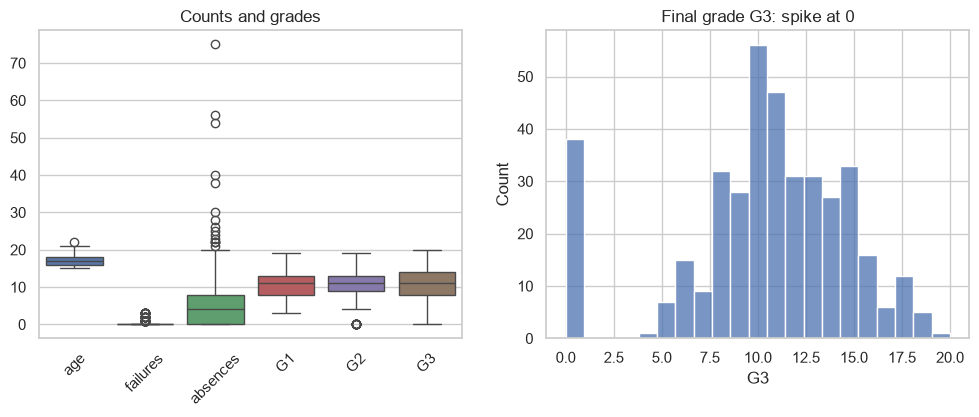

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df_raw[COUNT + GRADES], ax=axes[0])
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_title("Counts and grades")
sns.histplot(df_raw["G3"], bins=21, ax=axes[1])
axes[1].set_title("Final grade G3: spike at 0")
save(fig, "fig1_quality")

## 1.5 Data cleaning
- G3 = 0 → student did not take the final exam (dropout), not a real score → **removed**
- absences: capped at the 99th percentile
- duplicates: dropped (if any)

In [7]:
df = df_raw.drop_duplicates()
df = df[df["G3"] > 0].copy()
df["absences"] = df["absences"].clip(upper=df_raw["absences"].quantile(0.99))

pd.DataFrame({
    "before": [len(df_raw), int((df_raw["G3"] == 0).sum()), int(df_raw["absences"].max()), round(df_raw["G3"].mean(), 2)],
    "after": [len(df), int((df["G3"] == 0).sum()), int(df["absences"].max()), round(df["G3"].mean(), 2)],
}, index=["rows", "G3 = 0", "max absences", "mean G3"])

,before,after
rows,395.000,357.000
G3 = 0,38.000,0.000
max absences,75.000,38.000
mean G3,10.420,11.520


Effect of cleaning on the grades:

In [8]:
pd.DataFrame({
    "before": [df_raw["G2"].corr(df_raw["G3"]), int((df_raw["G3"] < 10).sum())],
    "after": [df["G2"].corr(df["G3"]), int((df["G3"] < 10).sum())],
}, index=["r(G2, G3)", "failing students (G3 < 10)"]).round(3)

,before,after
"r(G2, G3)",0.905,0.966
failing students (G3 < 10),130.000,92.000


## 1.6 Data transformation
- Binary → 0/1, nominal → one-hot, ordinal kept as ordered codes
- Standardization (z-score) before PCA (ages ~15-22, absences ~0-30, ratings 1-5)

In [9]:
BIN_MAP = {"yes": 1, "no": 0, "F": 0, "M": 1, "GP": 0, "MS": 1, "U": 1, "R": 0,
           "LE3": 0, "GT3": 1, "A": 0, "T": 1}
df_encoded = df.copy()
df_encoded[BINARY] = df[BINARY].apply(lambda s: s.map(BIN_MAP))
df_encoded = pd.get_dummies(df_encoded, columns=NOMINAL, dtype=int)
print("encoded shape:", df_encoded.shape)

FEATURES = ORDINAL + COUNT + BINARY            # used for PCA (grades = label side, one-hot = analysed with chi-square)
X = pd.DataFrame(StandardScaler().fit_transform(df_encoded[FEATURES]), columns=FEATURES, index=df.index)
X.describe().loc[["mean", "std"]].round(2)

encoded shape: (357, 46)


,Medu,Fedu,traveltime,studytime,famrel,freetime,goout,Dalc,Walc,health,age,failures,absences,school,sex,address,famsize,Pstatus,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic
mean,0.000,0.000,0.000,0.000,-0.000,-0.000,-0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,-0.000,-0.000,0.000,0.000,-0.000,0.000,-0.000,-0.000,0.000,-0.000,-0.000,-0.000,0.000
std,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000


## 1.7 Label
`G3` (0-20) → **regression**. `pass` = G3 ≥ 10 → **binary classification** (used to colour plots).

In [10]:
df["pass"] = (df["G3"] >= 10).astype(int)
df_encoded["pass"] = df["pass"]
print(df["pass"].value_counts())
print(f"pass rate: {df['pass'].mean() * 100:.1f}%")

pass
1    265
0     92
Name: count, dtype: int64
pass rate: 74.2%


## 1.8 Statistics

In [11]:
NUM = ORDINAL + COUNT + GRADES
pd.DataFrame({"mean": df[NUM].mean(), "variance": df[NUM].var()}).round(2)

,mean,variance
Medu,2.800,1.200
Fedu,2.550,1.180
traveltime,1.430,0.470
studytime,2.040,0.690
famrel,3.960,0.780
freetime,3.250,1.020
goout,3.100,1.190
Dalc,1.500,0.850
Walc,2.330,1.680
health,3.550,1.970


In [12]:
cov = df[NUM].cov()
corr = df[NUM].corr()
cov.round(2)

,Medu,Fedu,traveltime,studytime,famrel,freetime,goout,Dalc,Walc,health,age,failures,absences,G1,G2,G3
Medu,1.200,0.720,-0.130,0.050,-0.010,0.020,0.090,0.010,-0.070,-0.070,-0.190,-0.160,0.640,0.610,0.700,0.670
Fedu,0.720,1.180,-0.140,-0.030,-0.010,-0.030,0.050,-0.020,-0.030,0.010,-0.190,-0.190,0.090,0.570,0.610,0.560
traveltime,-0.130,-0.140,0.470,-0.050,-0.010,-0.010,0.030,0.100,0.120,0.000,0.090,0.060,0.010,-0.190,-0.240,-0.220
studytime,0.050,-0.030,-0.050,0.690,0.040,-0.130,-0.040,-0.150,-0.270,-0.080,0.000,-0.070,-0.500,0.380,0.310,0.340
famrel,-0.010,-0.010,-0.010,0.040,0.780,0.120,0.030,-0.060,-0.150,0.130,0.070,-0.000,-0.480,0.030,-0.010,0.110
freetime,0.020,-0.030,-0.010,-0.130,0.120,1.020,0.310,0.190,0.170,0.120,0.000,0.070,-0.320,0.020,-0.050,-0.070
goout,0.090,0.050,0.030,-0.040,0.030,0.310,1.190,0.280,0.630,-0.010,0.180,0.090,0.740,-0.530,-0.530,-0.620
Dalc,0.010,-0.020,0.100,-0.150,-0.060,0.190,0.280,0.850,0.770,0.110,0.170,0.100,0.800,-0.380,-0.370,-0.420
Walc,-0.070,-0.030,0.120,-0.270,-0.150,0.170,0.630,0.770,1.680,0.200,0.200,0.150,1.340,-0.740,-0.720,-0.790
health,-0.070,0.010,0.000,-0.080,0.130,0.120,-0.010,0.110,0.200,1.970,-0.090,0.040,-0.420,-0.330,-0.260,-0.370


In [13]:
for c in NOMINAL:
    display(df[c].value_counts(normalize=True).round(3).to_frame(c))
chi2_table(df, BINARY + NOMINAL, "pass").sort_values("Cramér's V", ascending=False)

,Mjob
Mjob,
other,0.356
services,0.263
teacher,0.151
at_home,0.140
health,0.090


,Fjob
Fjob,
other,0.549
services,0.280
teacher,0.073
health,0.050
at_home,0.048


,reason
reason,
course,0.353
reputation,0.277
home,0.272
other,0.098


,guardian
guardian,
mother,0.695
father,0.230
other,0.076


,feature,mode,chi-square,p-value,Cramér's V
5,schoolsup,no,9.000,0.003,0.159
13,Mjob,other,4.400,0.349,0.112
16,guardian,mother,4.300,0.119,0.109
10,higher,yes,3.300,0.071,0.095
14,Fjob,other,2.800,0.586,0.089
6,famsup,yes,1.600,0.208,0.067
15,reason,course,1.400,0.707,0.062
1,sex,F,0.900,0.354,0.049
11,internet,yes,0.700,0.402,0.044
2,address,U,0.500,0.482,0.037


In [14]:
# pass rate per category
fail_group = pd.cut(df["failures"], [-1, 0, 1, 99], labels=["0", "1", ">=2"])
rates = {"failures": df.groupby(fail_group, observed=True)["pass"].mean(),
         "schoolsup": df.groupby("schoolsup")["pass"].mean(),
         "higher": df.groupby("higher")["pass"].mean()}
print("r(failures, G3) =", round(df["failures"].corr(df["G3"]), 3))
pd.concat(rates).mul(100).round(1).to_frame("pass rate %")

r(failures, G3) = -0.294


pass rate %
failures  0         79.600
          1         60.000
          >=2       30.400
schoolsup no        77.200
          yes       56.000
higher    no        50.000
          yes       75.200

## 1.9 Correlation

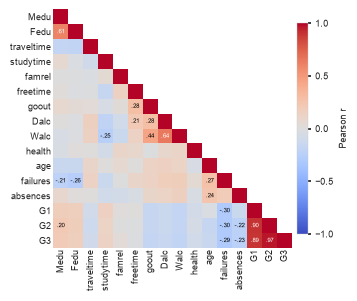

r
G2   G3   0.966
G1   G2   0.902
     G3   0.892
Dalc Walc 0.645
Medu Fedu 0.608

In [15]:
n = len(corr)
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(3.4, 3.1))
im = ax.imshow(np.ma.array(corr.values, mask=mask), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(n)); ax.set_xticklabels(corr.columns, rotation=90, fontsize=6.2)
ax.set_yticks(range(n)); ax.set_yticklabels(corr.index, fontsize=6.2)
ax.tick_params(length=0, pad=1.5)
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
for i in range(n):
    for j in range(i):
        r = corr.values[i, j]
        if abs(r) >= 0.2:
            ax.text(j, i, f"{r:.2f}".replace("0.", "."), ha="center", va="center",
                    fontsize=4.0, color="white" if abs(r) > 0.6 else "black")
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02, ticks=[-1, -0.5, 0, 0.5, 1])
cb.ax.grid(False); cb.outline.set_linewidth(0.3)
cb.ax.tick_params(labelsize=6.2, length=2); cb.set_label("Pearson r", fontsize=6.7)
fig.savefig(FIG / "fig2_corr_student.png", dpi=300, bbox_inches="tight", pad_inches=0.03)
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
top = pairs.reindex(pairs.abs().sort_values(ascending=False).index).head(5)
top.round(3).to_frame("r")

In [16]:
m = corr.drop(index=GRADES, columns=GRADES).to_numpy()
weak = np.abs(m[np.triu_indices(len(m), 1)]) <= 0.2
print(f"pairs without grades having |r| <= 0.2: {weak.mean() * 100:.0f}%")
ratio = df["absences"].var() / df_encoded[FEATURES].drop(columns="absences").var().max()
print(f"variance of absences = {ratio:.1f} x the largest other PCA input")

pairs without grades having |r| <= 0.2: 86%
variance of absences = 24.7 x the largest other PCA input


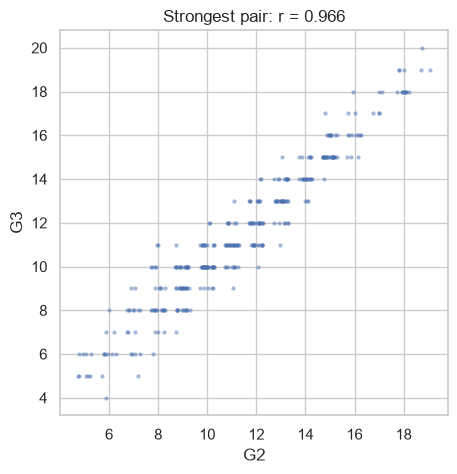

In [17]:
a, b = top.index[0]
fig, ax = plt.subplots(figsize=(5, 5))
np.random.seed(SEED)                     # jitter is random: fix it so the figure is reproducible
sns.stripplot(x=df[a], y=df[b], jitter=0.3, size=3, alpha=0.5, ax=ax, native_scale=True)
ax.set_title(f"Strongest pair: r = {corr.loc[a, b]:.3f}")
save(fig, "fig3_strongest_pair")

# Part 2 — PCA

## 2.1 Apply PCA
Input = standardized features `X` (label removed). Steps from slide 27: centre → covariance matrix → eigenvectors sorted by eigenvalue → project.

In [18]:
C = np.cov(X.to_numpy().T)                      # covariance matrix (X is already centred)
eigvals, eigvecs = np.linalg.eigh(C)
eigvals = eigvals[np.argsort(eigvals)[::-1]]       # sort by eigenvalue, largest first

pca = PCA(random_state=SEED).fit(X)                 # keep all components
Z = pca.transform(X)                                # projected data
print("Manual eigenvalues == sklearn:", np.allclose(eigvals, pca.explained_variance_))

Manual eigenvalues == sklearn: True


Why standardize: PCA on the **unscaled** features.

In [19]:
raw = df_encoded[FEATURES]
pca_raw = PCA(random_state=SEED).fit(raw)
top_feature = raw.columns[np.abs(pca_raw.components_[0]).argmax()]
print(f"unscaled PC1 explains {pca_raw.explained_variance_ratio_[0] * 100:.1f}% and is dominated by {top_feature}")

unscaled PC1 explains 76.4% and is dominated by absences


## 2.2 Explained variance

In [20]:
ev = pd.DataFrame({
    "eigenvalue": pca.explained_variance_,
    "explained %": pca.explained_variance_ratio_ * 100,
    "cumulative %": np.cumsum(pca.explained_variance_ratio_) * 100,
}, index=[f"PC{i}" for i in range(1, pca.n_components_ + 1)]).round(2)

k_for = {t: int(np.argmax(ev["cumulative %"].to_numpy() >= t) + 1) for t in (80, 90, 95)}
print("PCs needed:", {f"{t}%": k for t, k in k_for.items()})
print("Kaiser rule (eigenvalue > 1):", int((ev["eigenvalue"] > 1).sum()), "PCs")
print(f"ratio largest / smallest eigenvalue: {pca.explained_variance_[0] / pca.explained_variance_[-1]:.0f}")
ev

PCs needed: {'80%': 17, '90%': 20, '95%': 23}
Kaiser rule (eigenvalue > 1): 10 PCs
ratio largest / smallest eigenvalue: 11


,eigenvalue,explained %,cumulative %
PC1,3.010,11.560,11.560
PC2,2.250,8.640,20.200
PC3,1.710,6.550,26.750
PC4,1.460,5.610,32.360
PC5,1.410,5.420,37.780
PC6,1.350,5.170,42.950
PC7,1.220,4.690,47.650
PC8,1.180,4.530,52.170
PC9,1.090,4.170,56.340
PC10,1.050,4.020,60.360


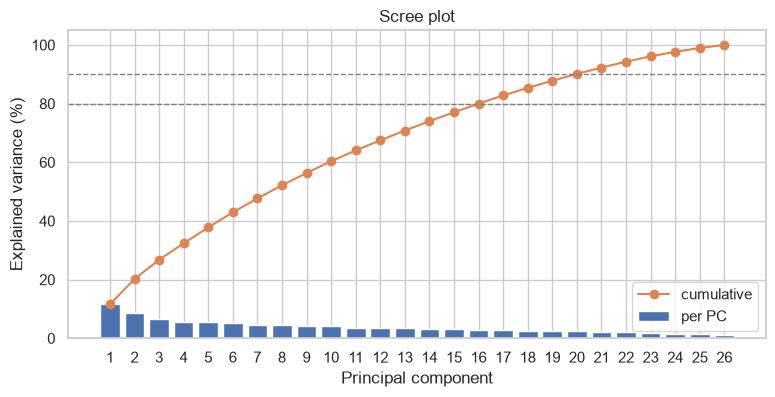

In [21]:
x = np.arange(1, len(ev) + 1)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x, ev["explained %"], label="per PC")
ax.plot(x, ev["cumulative %"], "o-", color="C1", label="cumulative")
for t in (80, 90):
    ax.axhline(t, ls="--", c="gray", lw=1)
ax.set(xlabel="Principal component", ylabel="Explained variance (%)", xticks=x, title="Scree plot")
ax.legend()
save(fig, "fig4_explained_variance")

## 2.3 Highest vs lowest variance components
Same axis scale on both plots: the last PCs barely move.

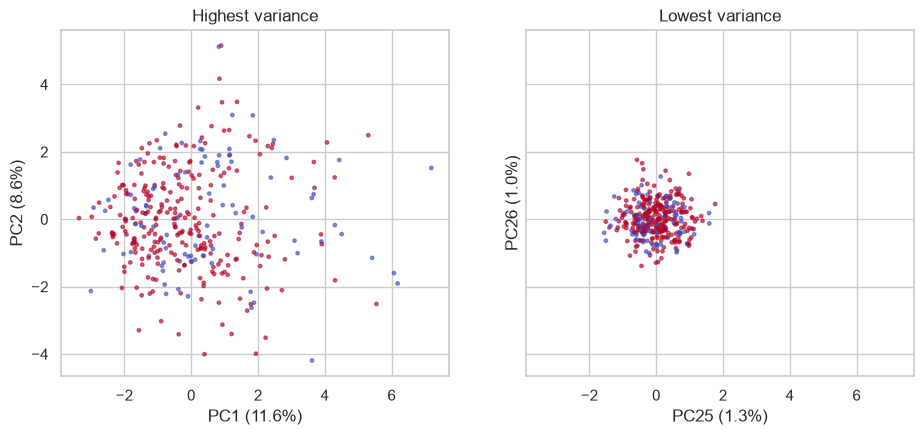

In [22]:
sample = np.arange(len(Z))
y = df["pass"].to_numpy()
d = Z.shape[1]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharex=True, sharey=True)
for ax, (i, j) in zip(axes, [(0, 1), (d - 2, d - 1)]):
    ax.scatter(Z[sample, i], Z[sample, j], c=y[sample], cmap="coolwarm", s=6, alpha=0.6)
    ax.set(xlabel=f"PC{i + 1} ({pca.explained_variance_ratio_[i] * 100:.1f}%)",
           ylabel=f"PC{j + 1} ({pca.explained_variance_ratio_[j] * 100:.1f}%)")
axes[0].set_title("Highest variance")
axes[1].set_title("Lowest variance")
save(fig, "fig5_high_vs_low_pcs")

Spread (standard deviation) and meaning of the last two PCs.

In [23]:
sd = np.sqrt(pca.explained_variance_)
print(f"std PC1 = {sd[0]:.2f}, PC{d - 1} = {sd[-2]:.2f}, PC{d} = {sd[-1]:.2f}")
last = pd.DataFrame(pca.components_[-2:].T, index=X.columns, columns=[f"PC{d - 1}", f"PC{d}"])
last[last.abs().max(axis=1) > 0.2].round(2)          # features that build the last PCs

std PC1 = 1.74, PC25 = 0.59, PC26 = 0.52


,PC25,PC26
Medu,-0.550,0.240
Fedu,0.580,-0.190
studytime,0.250,0.040
goout,-0.100,-0.310
Dalc,-0.180,-0.500
Walc,0.200,0.690
age,-0.210,0.110
absences,0.210,-0.060


In [24]:
pc2_by_class = pd.Series(Z[:, 1]).groupby(y).mean().round(2)
pc2_by_class.index = ['Fail', 'Pass']
pc2_by_class.to_frame("mean PC2 score")

,mean PC2 score
Fail,0.100
Pass,-0.030


## 2.4 Varying the number of components k

In [25]:
rows = []
for k in range(1, X.shape[1] + 1):
    p = PCA(n_components=k, random_state=SEED).fit(X)
    X_back = p.inverse_transform(p.transform(X))            # reconstruct (slide 33)
    rows.append({"k": k,
                 "variance kept %": p.explained_variance_ratio_.sum() * 100,
                 "reconstruction MSE": np.mean((X.to_numpy() - X_back) ** 2),
                 "dimensions removed %": (1 - k / X.shape[1]) * 100})
vary = pd.DataFrame(rows).round(3)
# standardized inputs: reconstruction MSE = share of variance discarded
print("MSE == 1 - variance kept:", np.allclose(vary["reconstruction MSE"], 1 - vary["variance kept %"] / 100, atol=1e-3))
vary

MSE == 1 - variance kept: True


,k,variance kept %,reconstruction MSE,dimensions removed %
0,1,11.558,0.884,96.154
1,2,20.200,0.798,92.308
2,3,26.751,0.732,88.462
3,4,32.363,0.676,84.615
4,5,37.784,0.622,80.769
5,6,42.953,0.570,76.923
6,7,47.648,0.524,73.077
7,8,52.174,0.478,69.231
8,9,56.343,0.437,65.385
9,10,60.359,0.396,61.538


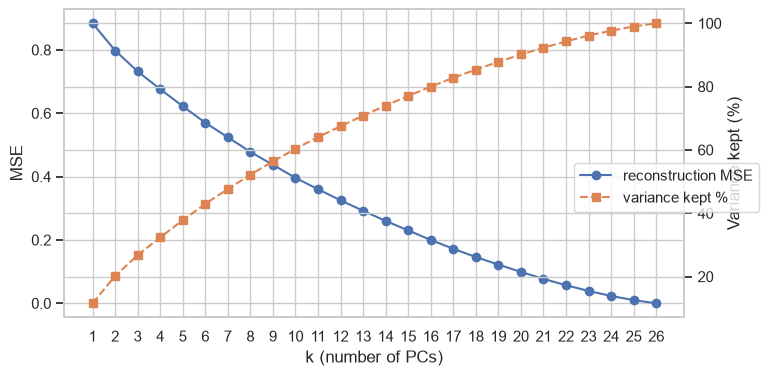

In [26]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(vary["k"], vary["reconstruction MSE"], "o-", label="reconstruction MSE")
ax2 = ax.twinx()
ax2.plot(vary["k"], vary["variance kept %"], "s--", color="C1", label="variance kept %")
ax.set(xlabel="k (number of PCs)", ylabel="MSE", xticks=vary["k"])
ax2.set_ylabel("Variance kept (%)")
fig.legend(loc="center right")
save(fig, "fig6_vary_k")

## 2.5 2D visualization (PC1 vs PC2)

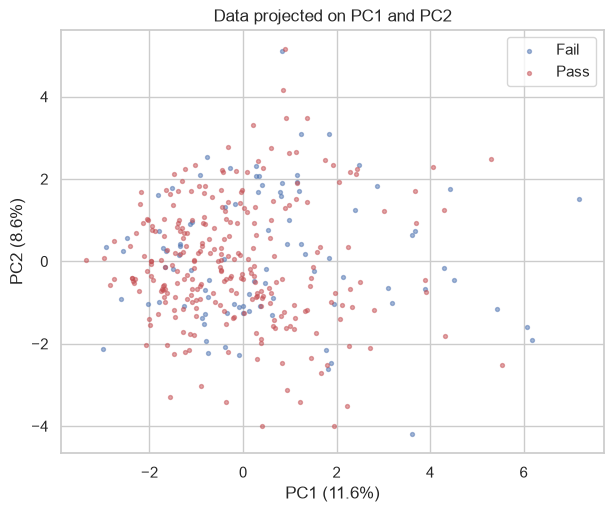

In [27]:
r = pca.explained_variance_ratio_ * 100
fig, ax = plt.subplots(figsize=(7, 5.5))
for value, name, color in [(0, "Fail", "C0"), (1, "Pass", "C3")]:
    m = sample[y[sample] == value]
    ax.scatter(Z[m, 0], Z[m, 1], s=8, alpha=0.5, c=color, label=name)
ax.set(xlabel=f"PC1 ({r[0]:.1f}%)", ylabel=f"PC2 ({r[1]:.1f}%)", title="Data projected on PC1 and PC2")
ax.legend()
save(fig, "fig7_pca_2d")

## 2.6 Original vs PCA representation
Loadings = weight of each original feature in a PC (how to interpret a PC).

,PC1,PC2,PC3
Walc,0.332,0.363,0.009
Dalc,0.311,0.350,0.024
failures,0.300,-0.060,0.072
age,0.290,-0.072,0.375
Medu,-0.257,0.378,0.138
Fedu,-0.252,0.341,0.092
school,0.249,-0.104,0.223
higher,-0.242,0.106,0.044
traveltime,0.241,-0.090,0.069
studytime,-0.227,-0.138,0.234


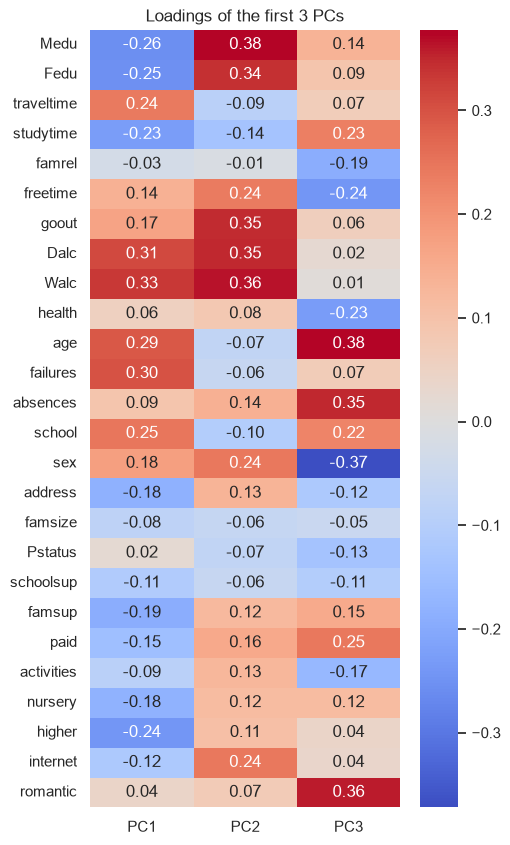

In [28]:
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])

fig, ax = plt.subplots(figsize=(5, 0.35 * len(loadings) + 1))
sns.heatmap(loadings, cmap="coolwarm", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Loadings of the first 3 PCs")
save(fig, "fig8_loadings")

loadings.round(3).sort_values("PC1", key=abs, ascending=False)

In [29]:
k = k_for[90]
pd.DataFrame({
    "Original": [X.shape[1], "100%", "Yes, each column is a real feature"],
    f"PCA (k = {k})": [k, f"{ev['cumulative %'].iloc[k - 1]:.1f}%", "Harder, each PC mixes all features"],
}, index=["Dimensions", "Variance kept", "Interpretable"])

,Original,PCA (k = 20)
Dimensions,26,20
Variance kept,100%,90.1%
Interpretable,"Yes, each column is a real feature","Harder, each PC mixes all features"


## 2.7 Extra: PCA with G1, G2 included
G1/G2 are earlier grades, strongly correlated with G3 (r ≈ 0.9). Does adding them make Pass / Fail easier to separate in 2D?

variance kept by 2 PCs with G1, G2: 19.9%


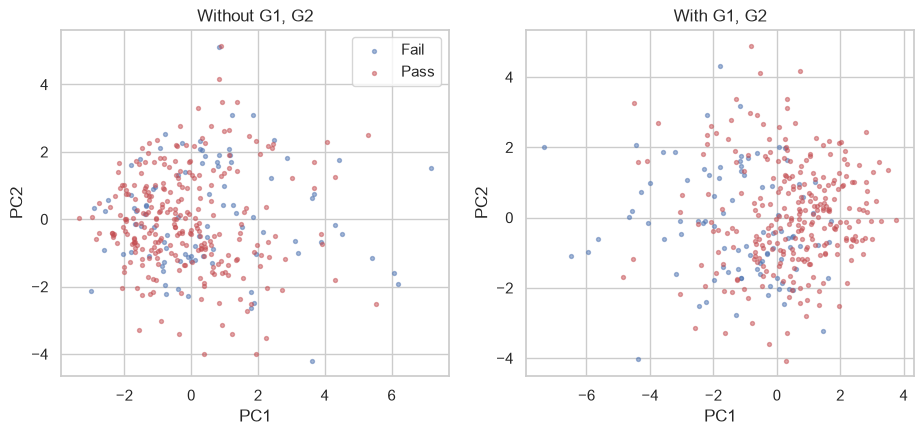

In [30]:
X_g = pd.DataFrame(StandardScaler().fit_transform(df_encoded[FEATURES + ["G1", "G2"]]), index=df.index)
pca_g = PCA(n_components=2, random_state=SEED).fit(X_g)
Z_g = pca_g.transform(X_g)
print(f"variance kept by 2 PCs with G1, G2: {pca_g.explained_variance_ratio_.sum() * 100:.1f}%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, data, title in [(axes[0], Z, "Without G1, G2"), (axes[1], Z_g, "With G1, G2")]:
    for value, name, color in [(0, "Fail", "C0"), (1, "Pass", "C3")]:
        m = y == value
        ax.scatter(data[m, 0], data[m, 1], s=8, alpha=0.5, c=color, label=name)
    ax.set(title=title, xlabel="PC1", ylabel="PC2")
axes[0].legend()
save(fig, "fig9_with_without_grades")

## 2.8 Separability: original vs PCA
Can a linear model still tell the classes apart? Class-weighted logistic regression, balanced accuracy, 5-fold stratified CV (chance = 50%).

In [31]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
model = LogisticRegression(class_weight="balanced", max_iter=2000)
inputs = {"all 26 original features": X, "PC1 + PC2": Z[:, :2], "PC1 + PC2, with G1, G2": Z_g}
pd.Series({name: cross_val_score(model, data, df["pass"], cv=cv, scoring="balanced_accuracy").mean() * 100
           for name, data in inputs.items()}, name="balanced accuracy %").round(1).to_frame()

,balanced accuracy %
all 26 original features,64.000
PC1 + PC2,57.500
"PC1 + PC2, with G1, G2",70.300
